In [2]:
import json 
import pandas as pd

In [3]:
# method 1 to read json data
json_file = open('loan_data_json.json')
data = json.load(json_file)

In [4]:
# method 2 
with open('loan_data_json.json') as json_file:
    data = json.load(json_file)

In [5]:
print(type(data))
print(str(data)[:500])

<class 'list'>
[{'credit.policy': 1, 'purpose': 'debt_consolidation', 'int.rate': 0.1189, 'installment': 829.1, 'log.annual.inc': 11.35040654, 'dti': 19.48, 'fico': 737, 'days.with.cr.line': 5639.958333, 'revol.bal': 28854, 'revol.util': 52.1, 'inq.last.6mths': 0, 'delinq.2yrs': 0, 'pub.rec': 0, 'not.fully.paid': 0}, {'credit.policy': 1, 'purpose': 'credit_card', 'int.rate': 0.1071, 'installment': 228.22, 'log.annual.inc': 11.08214255, 'dti': 14.29, 'fico': 707, 'days.with.cr.line': 2760, 'revol.bal': 33623, '


In [6]:
for key, value in data[0].items():
    print(key + ': ' + str(value))

credit.policy: 1
purpose: debt_consolidation
int.rate: 0.1189
installment: 829.1
log.annual.inc: 11.35040654
dti: 19.48
fico: 737
days.with.cr.line: 5639.958333
revol.bal: 28854
revol.util: 52.1
inq.last.6mths: 0
delinq.2yrs: 0
pub.rec: 0
not.fully.paid: 0


In [7]:
loan_data = pd.DataFrame(data)
loan_data

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9573,0,all_other,0.1461,344.76,12.180755,10.39,672,10474.000000,215372,82.1,2,0,0,1
9574,0,all_other,0.1253,257.70,11.141862,0.21,722,4380.000000,184,1.1,5,0,0,1
9575,0,debt_consolidation,0.1071,97.81,10.596635,13.09,687,3450.041667,10036,82.9,8,0,0,1
9576,0,home_improvement,0.1600,351.58,10.819778,19.18,692,1800.000000,0,3.2,5,0,0,1


In [8]:
loan_data['purpose'].unique()

<ArrowStringArray>
['debt_consolidation',        'credit_card',          'all_other',
   'home_improvement',     'small_business',     'major_purchase',
        'educational']
Length: 7, dtype: str

In [9]:
loan_data.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [10]:
loan_data['int.rate'].describe()

count    9578.000000
mean        0.122640
std         0.026847
min         0.060000
25%         0.103900
50%         0.122100
75%         0.140700
max         0.216400
Name: int.rate, dtype: float64

In [11]:
import numpy as np

In [12]:
# using exp to get annual income
income = np.exp(loan_data['log.annual.inc'])
income.head()

0    85000.000385
1    65000.000073
2    31999.999943
3    85000.000385
4    80799.999636
Name: log.annual.inc, dtype: float64

In [13]:
loan_data['annual_income'] = income

In [14]:
loan_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
 14  annual_income      9578 non-null   float64
dtypes: float64(7), int64(7), str(1)
memory usage: 1.2 MB


In [15]:
length = len(loan_data)
ficocat = []
for x in range(0, length):
    category = loan_data['fico'][x]
    if category >= 300 and category < 400:
        cat = "Very Poor"
    elif category >= 400 and category < 600:
        cat = "Poor"
    elif category >= 601 and category < 660:
        cat = "Fair"
    elif category >= 660 and category < 700:
        cat = "Good"
    elif category >= 700:
        cat = "Excellent"
    else:
        cat = "Unknown"
    ficocat.append(cat)

ficocat = pd.Series(ficocat)
loan_data['fico.category'] = ficocat

In [16]:
# method 2; could've been used for ficocat as well
# df.loc as conditional statements

# df.loc[df[columnname] condition, newcolumnname] = 'value if the condition is met'

#for interest rates, a new column is wanted. rate >0.12 then high, else low

loan_data.loc[loan_data['int.rate'] > 0.12, 'int.rate.type'] = 'High'
loan_data.loc[loan_data['int.rate'] <= 0.12, 'int.rate.type'] = 'Low'

In [17]:
loan_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
 14  annual_income      9578 non-null   float64
 15  fico.category      9578 non-null   str    
 16  int.rate.type      9578 non-null   

In [18]:
import matplotlib.pyplot as plt

In [19]:
catplot = loan_data.groupby(['fico.category']).size()  # number of loans/rows by fico.category
catplot

fico.category
Excellent    5357
Fair          489
Good         3732
dtype: int64

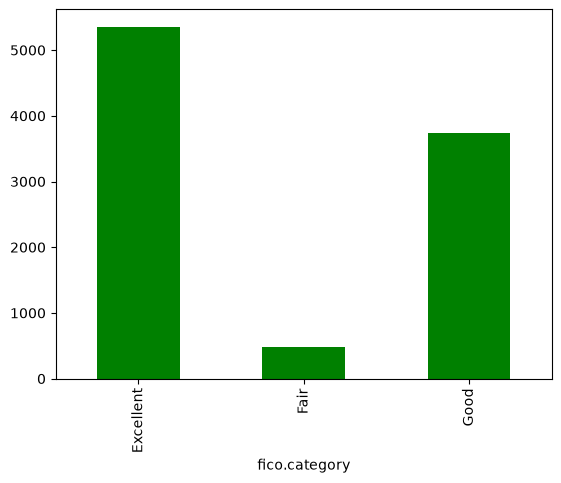

In [20]:
catplot.plot.bar(color='green', width=0.5)
plt.show()

In [21]:
purposecount = loan_data.groupby(['purpose']).size()
purposecount

purpose
all_other             2331
credit_card           1262
debt_consolidation    3957
educational            343
home_improvement       629
major_purchase         437
small_business         619
dtype: int64

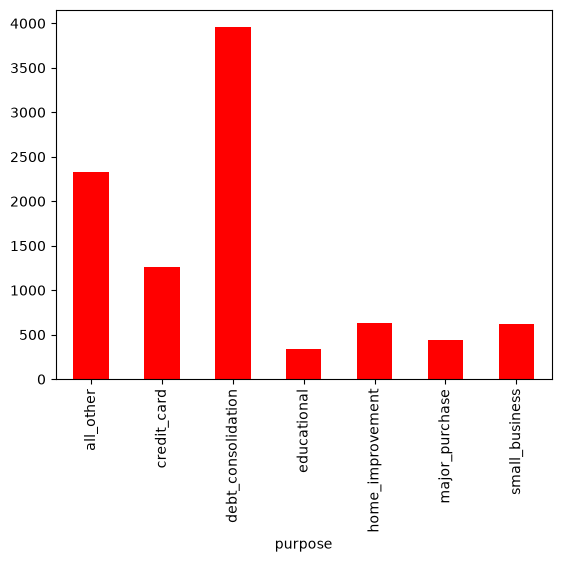

In [22]:
purposecount.plot.bar(color='red', width=0.5)
plt.show()

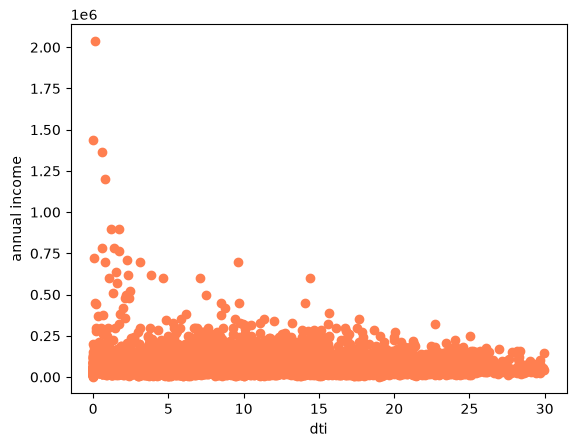

In [23]:
ypoint = loan_data['annual_income']
xpoint = loan_data['dti']
plt.scatter(xpoint, ypoint, color = 'coral')
plt.xlabel('dti')
plt.ylabel('annual income')
plt.show()

In [24]:
loan_data.to_csv('loan_cleaned.csv', index=True)